COCO subset of 5 classes, after removing:
- every image containing a crowd annotation (iscrowd=1)
- every image containing a person instance with less than 10 keypoints


## Step 1: Setup



In [2]:
from pathlib import Path
import json
import shutil
from collections import Counter, defaultdict
from tqdm import tqdm
import pandas as pd
import matplotlib.pyplot as plt

coco_root = Path(r"C:\Users\shiif\Downloads\coco2017")
annotations_dir = coco_root / "annotations"

train_annotation_path = annotations_dir / "instances_train2017.json"
val_annotation_path = annotations_dir / "instances_val2017.json"

train_keypoints_path = annotations_dir / "person_keypoints_train2017.json"
val_keypoints_path = annotations_dir / "person_keypoints_val2017.json"

print("Train annotations path:", train_annotation_path)
print("Val annotations path:  ", val_annotation_path)
print("Train keypoints path:  ", train_keypoints_path)
print("Val keypoints path:    ", val_keypoints_path)


Train annotations path: C:\Users\shiif\Downloads\coco2017\annotations\instances_train2017.json
Val annotations path:   C:\Users\shiif\Downloads\coco2017\annotations\instances_val2017.json
Train keypoints path:   C:\Users\shiif\Downloads\coco2017\annotations\person_keypoints_train2017.json
Val keypoints path:     C:\Users\shiif\Downloads\coco2017\annotations\person_keypoints_val2017.json


In [3]:
def load_coco_annotations(json_path):
    with open(json_path, "r") as f:
        return json.load(f)


def compute_class_statistics(coco_data):
    category_id_to_name = {cat["id"]: cat["name"] for cat in coco_data["categories"]}

    instance_counts = Counter()
    images_per_class = defaultdict(set)

    for ann in tqdm(coco_data["annotations"], desc="Processing annotations"):
        class_name = category_id_to_name[ann["category_id"]]
        instance_counts[class_name] += 1
        images_per_class[class_name].add(ann["image_id"])

    image_counts = {name: len(ids) for name, ids in images_per_class.items()}
    return instance_counts, image_counts


train_data = load_coco_annotations(train_annotation_path)
val_data = load_coco_annotations(val_annotation_path)

train_instance_counts_raw, train_image_counts_raw = compute_class_statistics(train_data)
val_instance_counts_raw, val_image_counts_raw = compute_class_statistics(val_data)

all_class_names = sorted(cat["name"] for cat in train_data["categories"])

coco_stats_raw_df = pd.DataFrame([
    {
        "Class": name,
        
        "Train Images": train_image_counts_raw.get(name, 0),
        "Train Instances": train_instance_counts_raw.get(name, 0),
        "Val Images": val_image_counts_raw.get(name, 0),
        "Val Instances": val_instance_counts_raw.get(name, 0),
    }
    for name in all_class_names
]).sort_values(by="Train Instances", ascending=False).reset_index(drop=True)

print("COCO class statistics (all classes, sorted by Train Instances):")
coco_stats_raw_df

Processing annotations: 100%|██████████| 36781/36781 [00:00<00:00, 1043215.41it/s]

COCO class statistics (all classes, sorted by Train Instances):


,Class,Train Images,Train Instances,Val Images,Val Instances
0,person,64115,262465,2693,11004
1,car,12251,43867,535,1932
2,chair,12774,38491,580,1791
3,book,5332,24715,230,1161
4,bottle,8501,24342,379,1025
...,...,...,...,...,...
75,scissors,947,1481,28,36
76,bear,960,1294,49,71
77,parking meter,705,1285,37,60
78,toaster,217,225,8,9


## Step 2: Remove Crowd Images and High-Keypoint-Person Images

In [4]:
def remove_crowd_images(coco_data):
    crowd_image_ids = set(
        ann["image_id"] for ann in coco_data["annotations"] if ann.get("iscrowd", 0) == 1
    )

    original_image_count = len(coco_data["images"])
    original_annotation_count = len(coco_data["annotations"])

    filtered_images = [img for img in coco_data["images"] if img["id"] not in crowd_image_ids]
    filtered_annotations = [ann for ann in coco_data["annotations"] if ann["image_id"] not in crowd_image_ids]

    filtered_data = {
        "images": filtered_images,
        "annotations": filtered_annotations,
        "categories": coco_data["categories"],
    }

    counts = {
        "original_images": original_image_count,
        "original_annotations": original_annotation_count,
        "removed_images": len(crowd_image_ids),
        "images_left": len(filtered_images),
        "annotations_left": len(filtered_annotations),
    }

    return filtered_data, counts


train_data_no_crowd, train_crowd_counts = remove_crowd_images(train_data)
val_data_no_crowd, val_crowd_counts = remove_crowd_images(val_data)

print("Train split — after removing iscrowd=1 images:")
print(f"  Images before: {train_crowd_counts['original_images']:,}")
print(f"  Images removed (iscrowd=1): {train_crowd_counts['removed_images']:,}")
print(f"  Images left: {train_crowd_counts['images_left']:,}")
print(f"  Annotations before: {train_crowd_counts['original_annotations']:,}")
print(f"  Annotations left: {train_crowd_counts['annotations_left']:,}")

print("\nVal split — after removing iscrowd=1 images:")
print(f"  Images before: {val_crowd_counts['original_images']:,}")
print(f"  Images removed (iscrowd=1): {val_crowd_counts['removed_images']:,}")
print(f"  Images left: {val_crowd_counts['images_left']:,}")
print(f"  Annotations before: {val_crowd_counts['original_annotations']:,}")
print(f"  Annotations left: {val_crowd_counts['annotations_left']:,}")

Train split — after removing iscrowd=1 images:
  Images before: 118,287
  Images removed (iscrowd=1): 9,115
  Images left: 109,172
  Annotations before: 860,001
  Annotations left: 654,212

Val split — after removing iscrowd=1 images:
  Images before: 5,000
  Images removed (iscrowd=1): 411
  Images left: 4,589
  Annotations before: 36,781
  Annotations left: 27,436


In [5]:
def build_keypoints_lookup(keypoints_json_path):
    keypoints_data = load_coco_annotations(keypoints_json_path)
    return {ann["id"]: ann.get("num_keypoints", 0) for ann in keypoints_data["annotations"]}

train_keypoints_lookup = build_keypoints_lookup(train_keypoints_path)
val_keypoints_lookup = build_keypoints_lookup(val_keypoints_path)

KEYPOINT_THRESHOLD = 10

def remove_low_keypoint_person_images(coco_data, keypoints_lookup, keypoint_threshold):
    category_id_to_name = {cat["id"]: cat["name"] for cat in coco_data["categories"]}
    person_category_id = 1

    #useful in future, ignore for now...next((cid for cid, name in category_id_to_name.items() if name == "person"), None)

    low_keypoint_image_ids = set()
    if person_category_id is not None:
        for ann in coco_data["annotations"]:
            if ann["category_id"] == person_category_id:
                num_keypoints = keypoints_lookup.get(ann["id"], 0)
                if num_keypoints <= keypoint_threshold:
                    low_keypoint_image_ids.add(ann["image_id"])

    original_image_count = len(coco_data["images"])
    original_annotation_count = len(coco_data["annotations"])

    filtered_images = [img for img in coco_data["images"] if img["id"] not in low_keypoint_image_ids]
    filtered_annotations = [ann for ann in coco_data["annotations"] if ann["image_id"] not in low_keypoint_image_ids]

    filtered_data = {
        "images": filtered_images,
        "annotations": filtered_annotations,
        "categories": coco_data["categories"],
    }

    counts = {
        "original_images": original_image_count,
        "original_annotations": original_annotation_count,
        "removed_images": len(low_keypoint_image_ids),
        "images_left": len(filtered_images),
        "annotations_left": len(filtered_annotations),
    }

    return filtered_data, counts


train_data_clean, train_kp_counts = remove_low_keypoint_person_images(
    train_data_no_crowd, train_keypoints_lookup, KEYPOINT_THRESHOLD
)
val_data_clean, val_kp_counts = remove_low_keypoint_person_images(
    val_data_no_crowd, val_keypoints_lookup, KEYPOINT_THRESHOLD
)

print(f"Train: removing images having <= {KEYPOINT_THRESHOLD} keypoints:")
print(f"  Images before (post-crowd-removal): {train_kp_counts['original_images']:,}")
print(f"  Images removed (low-keypoint person): {train_kp_counts['removed_images']:,}")
print(f"  Images left: {train_kp_counts['images_left']:,}")
print(f"  Annotations before: {train_kp_counts['original_annotations']:,}")
print(f"  Annotations left: {train_kp_counts['annotations_left']:,}")

print(f"\nVal: removing images having <= {KEYPOINT_THRESHOLD} keypoints:")
print(f"  Images before (post-crowd-removal): {val_kp_counts['original_images']:,}")
print(f"  Images removed (low-keypoint person): {val_kp_counts['removed_images']:,}")
print(f"  Images left: {val_kp_counts['images_left']:,}")
print(f"  Annotations before: {val_kp_counts['original_annotations']:,}")
print(f"  Annotations left: {val_kp_counts['annotations_left']:,}")

Train: removing images having <= 10 keypoints:
  Images before (post-crowd-removal): 109,172
  Images removed (low-keypoint person): 37,218
  Images left: 71,954
  Annotations before: 654,212
  Annotations left: 309,433

Val: removing images having <= 10 keypoints:
  Images before (post-crowd-removal): 4,589
  Images removed (low-keypoint person): 1,556
  Images left: 3,033
  Annotations before: 27,436
  Annotations left: 13,180


## Step 3: Compute Statistics on the Cleaned Data



In [6]:
train_instance_counts, train_image_counts = compute_class_statistics(train_data_clean)
val_instance_counts, val_image_counts = compute_class_statistics(val_data_clean)

all_class_names = sorted(cat["name"] for cat in train_data_clean["categories"])

coco_stats_df = pd.DataFrame([
    {
        "Class": name,
        "Train Images": train_image_counts.get(name, 0),
        "Train Instances": train_instance_counts.get(name, 0),
        "Val Images": val_image_counts.get(name, 0),
        "Val Instances": val_instance_counts.get(name, 0),
    }
    for name in all_class_names
]).sort_values(by="Train Instances", ascending=False).reset_index(drop=True)

pd.set_option("display.max_rows", None)

print("COCO class statistics after cleaning (sorted by Train Instances, descending):")
coco_stats_df

Processing annotations: 100%|██████████| 13180/13180 [00:00<00:00, 876570.63it/s]


COCO class statistics after cleaning (sorted by Train Instances, descending):


,Class,Train Images,Train Instances,Val Images,Val Instances
0,person,19767,28995,813,1160
1,car,5054,15532,232,793
2,chair,6350,13372,275,561
3,book,3448,11821,134,524
4,bottle,4845,11771,214,472
5,cup,5192,9632,205,420
6,bowl,4731,8560,199,339
7,dining table,6863,7684,276,306
8,broccoli,1639,5938,59,235
9,carrot,1281,5518,57,217


## Step 4: Select Five Classes




In [7]:
MIN_TRAIN_INSTANCES = 5000
MIN_VAL_INSTANCES = 400

qualifying_df = coco_stats_df[
    (coco_stats_df["Train Instances"] >= MIN_TRAIN_INSTANCES)
    & (coco_stats_df["Val Instances"] >= MIN_VAL_INSTANCES)
    
].sort_values(by="Train Instances", ascending=False)

selected_classes = qualifying_df["Class"].head(5).tolist()

print("Selected classes:")
for name in selected_classes:
    print(" -", name)

coco_stats_df[coco_stats_df["Class"].isin(selected_classes)].reset_index(drop=True)


Selected classes:
 - person
 - car
 - chair
 - book
 - bottle


,Class,Train Images,Train Instances,Val Images,Val Instances
0,person,19767,28995,813,1160
1,car,5054,15532,232,793
2,chair,6350,13372,275,561
3,book,3448,11821,134,524
4,bottle,4845,11771,214,472


## Step 5: Create Dataset Directory




In [8]:
dataset_root = Path("datasets") / "coco_instance_balanced5_iscrowd0_10kp"

if dataset_root.exists():
    shutil.rmtree(dataset_root)

for folder in [
    dataset_root / "images" / "train",
    dataset_root / "images" / "val",
    dataset_root / "labels" / "train",
    dataset_root / "labels" / "val",
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Dataset folder structure created at:", dataset_root.resolve())


Dataset folder structure created at: C:\Users\shiif\Downloads\yoloduke\datasets\coco_instance_balanced5_iscrowd0_10kp


## Step 6: Build Class and Image Lookups




In [9]:
class_name_to_index = {name: idx for idx, name in enumerate(selected_classes)}

category_id_to_name = {cat["id"]: cat["name"] for cat in train_data_clean["categories"]}
category_id_to_new_index = {
    cat_id: class_name_to_index[name]
    for cat_id, name in category_id_to_name.items()
    if name in class_name_to_index
}

def build_image_info(coco_data):
    return {img["id"]: {"file_name": img["file_name"], "width": img["width"], "height": img["height"]}
            for img in coco_data["images"]}

train_image_info = build_image_info(train_data_clean)
val_image_info = build_image_info(val_data_clean)

print("Class index mapping:")
for name, idx in class_name_to_index.items():
    print(f"  {idx}: {name}")


Class index mapping:
  0: person
  1: car
  2: chair
  3: book
  4: bottle


## Step 7: Filter Annotations




In [10]:
def filter_annotations_by_image(coco_data, category_id_to_new_index):
    selected_ids = set(category_id_to_new_index.keys())
    annotations_by_image = defaultdict(list)

    for ann in tqdm(coco_data["annotations"], desc="Filtering annotations"):
        if ann["category_id"] in selected_ids:
            annotations_by_image[ann["image_id"]].append(ann)
            
    return annotations_by_image

train_annotations_by_image = filter_annotations_by_image(train_data_clean, category_id_to_new_index)
val_annotations_by_image = filter_annotations_by_image(val_data_clean, category_id_to_new_index)

print("Training images with a selected class:  ", len(train_annotations_by_image))
print("Validation images with a selected class:", len(val_annotations_by_image))


Filtering annotations: 100%|██████████| 13180/13180 [00:00<00:00, 1248186.38it/s]

Training images with a selected class:   31933
Validation images with a selected class: 1357


## Step 8: Copy Images and Write YOLO Labels



In [11]:
def coco_bbox_to_yolo(bbox, image_width, image_height):
    x_min, y_min, box_width, box_height = bbox
    x_center = (x_min + box_width / 2) / image_width
    y_center = (y_min + box_height / 2) / image_height
    return x_center, y_center, box_width / image_width, box_height / image_height


def build_dataset_split(split_name, source_images_dir, image_info, annotations_by_image, category_id_to_new_index):
    destination_images_dir = dataset_root / "images" / split_name
    destination_labels_dir = dataset_root / "labels" / split_name

    for image_id, annotations in tqdm(annotations_by_image.items(), desc=f"Writing {split_name} set"):
        info = image_info[image_id]
        file_name = info["file_name"]

        shutil.copy(source_images_dir / file_name, destination_images_dir / file_name)

        label_lines = []
        for ann in annotations:
            class_index = category_id_to_new_index[ann["category_id"]]
            x_c, y_c, w, h = coco_bbox_to_yolo(ann["bbox"], info["width"], info["height"])
            label_lines.append(f"{class_index} {x_c:.6f} {y_c:.6f} {w:.6f} {h:.6f}")

        label_path = destination_labels_dir / (Path(file_name).stem + ".txt")
        with open(label_path, "w") as f:
            f.write("\n".join(label_lines))


build_dataset_split("train", coco_root / "train2017", train_image_info,
                     train_annotations_by_image, category_id_to_new_index)
build_dataset_split("val", coco_root / "val2017", val_image_info,
                     val_annotations_by_image, category_id_to_new_index)

print("Dataset created at:", dataset_root.resolve())


Writing val set: 100%|██████████| 1357/1357 [00:05<00:00, 268.02it/s]

Dataset created at: C:\Users\shiif\Downloads\yoloduke\datasets\coco_instance_balanced5_iscrowd0_10kp


In [12]:
import random

random.seed(42)  

index_to_class_name = {idx: name for name, idx in class_name_to_index.items()}

current_instance_counts = {name: 0 for name in selected_classes}
for image_id, annotations in train_annotations_by_image.items():
    for ann in annotations:
        class_name = index_to_class_name[category_id_to_new_index[ann["category_id"]]]
        current_instance_counts[class_name] += 1

print("Current instances per class (before balancing):")
for name in selected_classes:
    print(f"  {name}: {current_instance_counts[name]:,}")

target_instances = min(current_instance_counts.values())
print(f"\nTarget instances per class: {target_instances:,}")

image_ids_shuffled = list(train_annotations_by_image.keys())
random.shuffle(image_ids_shuffled)

balanced_instance_counts = {name: 0 for name in selected_classes}
balanced_annotations_by_image = {}

for image_id in image_ids_shuffled:
    annotations = train_annotations_by_image[image_id]

    classes_in_image = set(
        index_to_class_name[category_id_to_new_index[ann["category_id"]]]
        for ann in annotations
    )

    if all(balanced_instance_counts[name] < target_instances for name in classes_in_image):
        balanced_annotations_by_image[image_id] = annotations
        for ann in annotations:
            class_name = index_to_class_name[category_id_to_new_index[ann["category_id"]]]
            balanced_instance_counts[class_name] += 1

print("\nFinal instances per class (after undersampling):")
for name in selected_classes:
    print(f"  {name}: {balanced_instance_counts[name]:,}")

print(f"\nImages kept: {len(balanced_annotations_by_image):,} out of {len(train_annotations_by_image):,}")

Current instances per class (before balancing):
  person: 28,995
  car: 15,532
  chair: 13,372
  book: 11,821
  bottle: 11,771

Target instances per class: 11,771

Final instances per class (after undersampling):
  person: 11,773
  car: 11,772
  chair: 10,984
  book: 10,290
  bottle: 10,240

Images kept: 19,794 out of 31,933


In [13]:
# --- Create a new directory for the balanced (undersampled) dataset ---

balanced_dataset_root = Path("datasets") / "coco_instance_balanced5_undersampled"

if balanced_dataset_root.exists():
    shutil.rmtree(balanced_dataset_root)

for folder in [
    balanced_dataset_root / "images" / "train",
    balanced_dataset_root / "images" / "val",
    balanced_dataset_root / "labels" / "train",
    balanced_dataset_root / "labels" / "val",
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Balanced dataset folder structure created at:", balanced_dataset_root.resolve())

Balanced dataset folder structure created at: C:\Users\shiif\Downloads\yoloduke\datasets\coco_instance_balanced5_undersampled


In [14]:
# --- Copy the balanced train set into the new directory ---

def build_dataset_split_at(target_root, split_name, source_images_dir, image_info,
                            annotations_by_image, category_id_to_new_index):
    """Same logic as build_dataset_split, but takes the target root explicitly so it
    can write to balanced_dataset_root instead of the original dataset_root."""
    destination_images_dir = target_root / "images" / split_name
    destination_labels_dir = target_root / "labels" / split_name

    for image_id, annotations in tqdm(annotations_by_image.items(), desc=f"Writing {split_name} set"):
        info = image_info[image_id]
        file_name = info["file_name"]

        shutil.copy(source_images_dir / file_name, destination_images_dir / file_name)

        label_lines = []
        for ann in annotations:
            class_index = category_id_to_new_index[ann["category_id"]]
            x_c, y_c, w, h = coco_bbox_to_yolo(ann["bbox"], info["width"], info["height"])
            label_lines.append(f"{class_index} {x_c:.6f} {y_c:.6f} {w:.6f} {h:.6f}")

        label_path = destination_labels_dir / (Path(file_name).stem + ".txt")
        with open(label_path, "w") as f:
            f.write("\n".join(label_lines))


build_dataset_split_at(balanced_dataset_root, "train", coco_root / "train2017", train_image_info,
                        balanced_annotations_by_image, category_id_to_new_index)

print(f"Balanced train folder written with {len(balanced_annotations_by_image):,} images at:")
print(balanced_dataset_root.resolve())

Writing train set: 100%|██████████| 19794/19794 [01:24<00:00, 234.87it/s]

Balanced train folder written with 19,794 images at:
C:\Users\shiif\Downloads\yoloduke\datasets\coco_instance_balanced5_undersampled


## Write data.yaml


In [5]:
from pathlib import Path

# Define the dataset you want to use
dataset_root = Path(
    r"C:\Users\shiif\Downloads\yoloduke\datasets\coco_instance_balanced5_undersampled"
)

# Define your 5 classes
selected_classes = ["person", "car", "chair", "book", "bottle"]

# data.yaml location
data_yaml_path = Path(
    r"C:\Users\shiif\Downloads\yoloduke\data.yaml"
)

data_yaml_content = "# data.yaml — points to the balanced dataset output\n"
data_yaml_content += f"path: {dataset_root.as_posix()}\n"
data_yaml_content += "train: images/train\n"
data_yaml_content += "val: images/val\n"
data_yaml_content += f"nc: {len(selected_classes)}\n"
data_yaml_content += "names:\n"

for idx, name in enumerate(selected_classes):
    data_yaml_content += f"  {idx}: {name}\n"

with open(data_yaml_path, "w") as f:
    f.write(data_yaml_content)

print(f"Wrote {data_yaml_path.resolve()}:\n")
print(data_yaml_content)

Wrote C:\Users\shiif\Downloads\yoloduke\data.yaml:

# data.yaml — points to the balanced dataset output
path: C:/Users/shiif/Downloads/yoloduke/datasets/coco_instance_balanced5_undersampled
train: images/train
val: images/val
nc: 5
names:
  0: person
  1: car
  2: chair
  3: book
  4: bottle



## yolov8s_5class.yaml

In [6]:
# --- Auto-write yolov8s_5class.yaml (architecture, nc tied to selected_classes) ---
model_yaml_path = Path("yolov8s_5class.yaml")

model_yaml_content = f"""# yolov8s_5class.yaml \u2014 customized from stock yolov8.yaml
# Renamed to include the 's' scale letter so Ultralytics correctly auto-selects
# the small-scale row below when this file is loaded as the model architecture.
# Only functional change from stock: nc set to {len(selected_classes)}.
nc: {len(selected_classes)}  # number of classes: was 80, now {len(selected_classes)} (our balanced COCO subset)
scales: # model compound scaling constants \u2014 unchanged
  n: [0.33, 0.25, 1024]
  s: [0.33, 0.50, 1024]
  m: [0.67, 0.75, 768]
  l: [1.00, 1.00, 512]
  x: [1.00, 1.25, 512]
# backbone \u2014 unchanged from stock yolov8.yaml, no architecture edits needed
backbone:
  - [-1, 1, Conv, [64, 3, 2]]   # 0-P1/2
  - [-1, 1, Conv, [128, 3, 2]]  # 1-P2/4
  - [-1, 3, C2f, [128, True]]
  - [-1, 1, Conv, [256, 3, 2]]  # 3-P3/8
  - [-1, 6, C2f, [256, True]]
  - [-1, 1, Conv, [512, 3, 2]]  # 5-P4/16
  - [-1, 6, C2f, [512, True]]
  - [-1, 1, Conv, [1024, 3, 2]] # 7-P5/32
  - [-1, 3, C2f, [1024, True]]
  - [-1, 1, SPPF, [1024, 5]]    # 9
# head \u2014 unchanged from stock yolov8.yaml
head:
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 6], 1, Concat, [1]]
  - [-1, 3, C2f, [512]]         # 12
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 4], 1, Concat, [1]]
  - [-1, 3, C2f, [256]]         # 15 (P3/8-small)
  - [-1, 1, Conv, [256, 3, 2]]
  - [[-1, 12], 1, Concat, [1]]
  - [-1, 3, C2f, [512]]         # 18 (P4/16-medium)
  - [-1, 1, Conv, [512, 3, 2]]
  - [[-1, 9], 1, Concat, [1]]
  - [-1, 3, C2f, [1024]]        # 21 (P5/32-large)
  - [[15, 18, 21], 1, Detect, [nc]]  # Detect(P3, P4, P5) \u2014 nc automatically = {len(selected_classes)}
"""

with open(model_yaml_path, "w") as f:
    f.write(model_yaml_content)

print(f"Wrote {{model_yaml_path.resolve()}}:\n")
print(model_yaml_content)


Wrote {model_yaml_path.resolve()}:

# yolov8s_5class.yaml — customized from stock yolov8.yaml
# Renamed to include the 's' scale letter so Ultralytics correctly auto-selects
# the small-scale row below when this file is loaded as the model architecture.
# Only functional change from stock: nc set to 5.
nc: 5  # number of classes: was 80, now 5 (our balanced COCO subset)
scales: # model compound scaling constants — unchanged
  n: [0.33, 0.25, 1024]
  s: [0.33, 0.50, 1024]
  m: [0.67, 0.75, 768]
  l: [1.00, 1.00, 512]
  x: [1.00, 1.25, 512]
# backbone — unchanged from stock yolov8.yaml, no architecture edits needed
backbone:
  - [-1, 1, Conv, [64, 3, 2]]   # 0-P1/2
  - [-1, 1, Conv, [128, 3, 2]]  # 1-P2/4
  - [-1, 3, C2f, [128, True]]
  - [-1, 1, Conv, [256, 3, 2]]  # 3-P3/8
  - [-1, 6, C2f, [256, True]]
  - [-1, 1, Conv, [512, 3, 2]]  # 5-P4/16
  - [-1, 6, C2f, [512, True]]
  - [-1, 1, Conv, [1024, 3, 2]] # 7-P5/32
  - [-1, 3, C2f, [1024, True]]
  - [-1, 1, SPPF, [1024, 5]]    # 9
# hea

## train_config_5class.yaml


In [8]:
# --- Auto-write train_config_5class.yaml, tied to this run's actual paths/epochs ---
train_cfg_path = Path("train_config_5class.yaml")

train_cfg_content = f"""# train_config_5class.yaml — pass this via cfg="train_config_5class.yaml"
task: detect
mode: train
model: {model_yaml_path.as_posix()}   # build from OUR custom nc=5 architecture, not the stock .pt
pretrained: yolov8s.pt       # explicit checkpoint string — transfer-learn matching
                              # (backbone + neck) layers from here; the Detect head
                              # is freshly initialized since its shape (nc={len(selected_classes)}) can't
                              # match the checkpoint's 80-class head
data: {data_yaml_path.as_posix()}
epochs: 100
patience: 50
batch: 16
imgsz: 640
optimizer: SGD
box: 7.5
cls: 0.5
dfl: 1.5
cls_pw: 0.0
# Everything else (lr0, lrf, momentum, weight_decay, augmentation, etc.)
# inherits Ultralytics' normal defaults automatically.
"""

with open(train_cfg_path, "w") as f:
    f.write(train_cfg_content)

print(f"Wrote {train_cfg_path.resolve()}:\n")
print(train_cfg_content)

Wrote C:\Users\shiif\Downloads\yoloduke\train_config_5class.yaml:

# train_config_5class.yaml — pass this via cfg="train_config_5class.yaml"
task: detect
mode: train
model: yolov8s_5class.yaml   # build from OUR custom nc=5 architecture, not the stock .pt
pretrained: yolov8s.pt       # explicit checkpoint string — transfer-learn matching
                              # (backbone + neck) layers from here; the Detect head
                              # is freshly initialized since its shape (nc=5) can't
                              # match the checkpoint's 80-class head
data: C:/Users/shiif/Downloads/yoloduke/data.yaml
epochs: 100
patience: 50
batch: 16
imgsz: 640
optimizer: SGD
box: 7.5
cls: 0.5
dfl: 1.5
cls_pw: 0.0
# Everything else (lr0, lrf, momentum, weight_decay, augmentation, etc.)
# inherits Ultralytics' normal defaults automatically.



In [9]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("❌ CUDA/GPU not available — training will use CPU")

CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
CUDA version: 12.1


In [10]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torch location:", torch.__file__)
print("CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: c:\Users\shiif\Downloads\yoloduke\.venv\Scripts\python.exe
PyTorch: 2.5.1+cu121
Torch location: c:\Users\shiif\Downloads\yoloduke\.venv\Lib\site-packages\torch\__init__.py
CUDA: 12.1
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## Train


In [11]:
from ultralytics import YOLO

# Build from OUR custom nc=5 architecture (not a stock .pt) — matches train_config_5class.yaml's `model:` field
model = YOLO(str(model_yaml_path))

# Everything else — pretrained checkpoin0  t, data, epochs, batch, optimizer, loss weights — comes from the cfg file
results = model.train(cfg=str(train_cfg_path))

print("Best weights saved to:", Path(results.save_dir) / "weights" / "best.pt")

New https://pypi.org/project/ultralytics/8.4.138 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.137  Python-3.11.9 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=train_config_5class.yaml, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:/Users/shiif/Downloads/yoloduke/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf

In [15]:
metrics = model.val()

print(f"mAP50-95: {metrics.box.map:.4f}")
print(f"mAP50:    {metrics.box.map50:.4f}")
print(f"mAP75:    {metrics.box.map75:.4f}")
print("Per-class mAP50-95:", dict(zip(selected_classes, metrics.box.maps)))

Ultralytics 8.4.137  Python-3.11.9 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
val: Fast image access  (ping: 0.10.0 ms, read: 794.1390.4 MB/s, size: 103.4 KB)
val: Scanning C:\Users\shiif\Downloads\yoloduke\datasets\coco_instance_balanced5_undersampled\labels\val.cache... 1357 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1357/1357  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 85/85 4.9it/s 17.5s0.2s
                   all       1357       3510      0.666       0.61      0.628      0.451
                person        813       1160      0.943      0.949      0.964      0.801
                   car        232        793      0.667      0.612      0.644      0.405
                 chair        275        561        0.6      0.569      0.597      0.434
                  book        134        524      0.485      0.263      0.268      0.152
                bottle        214        472     

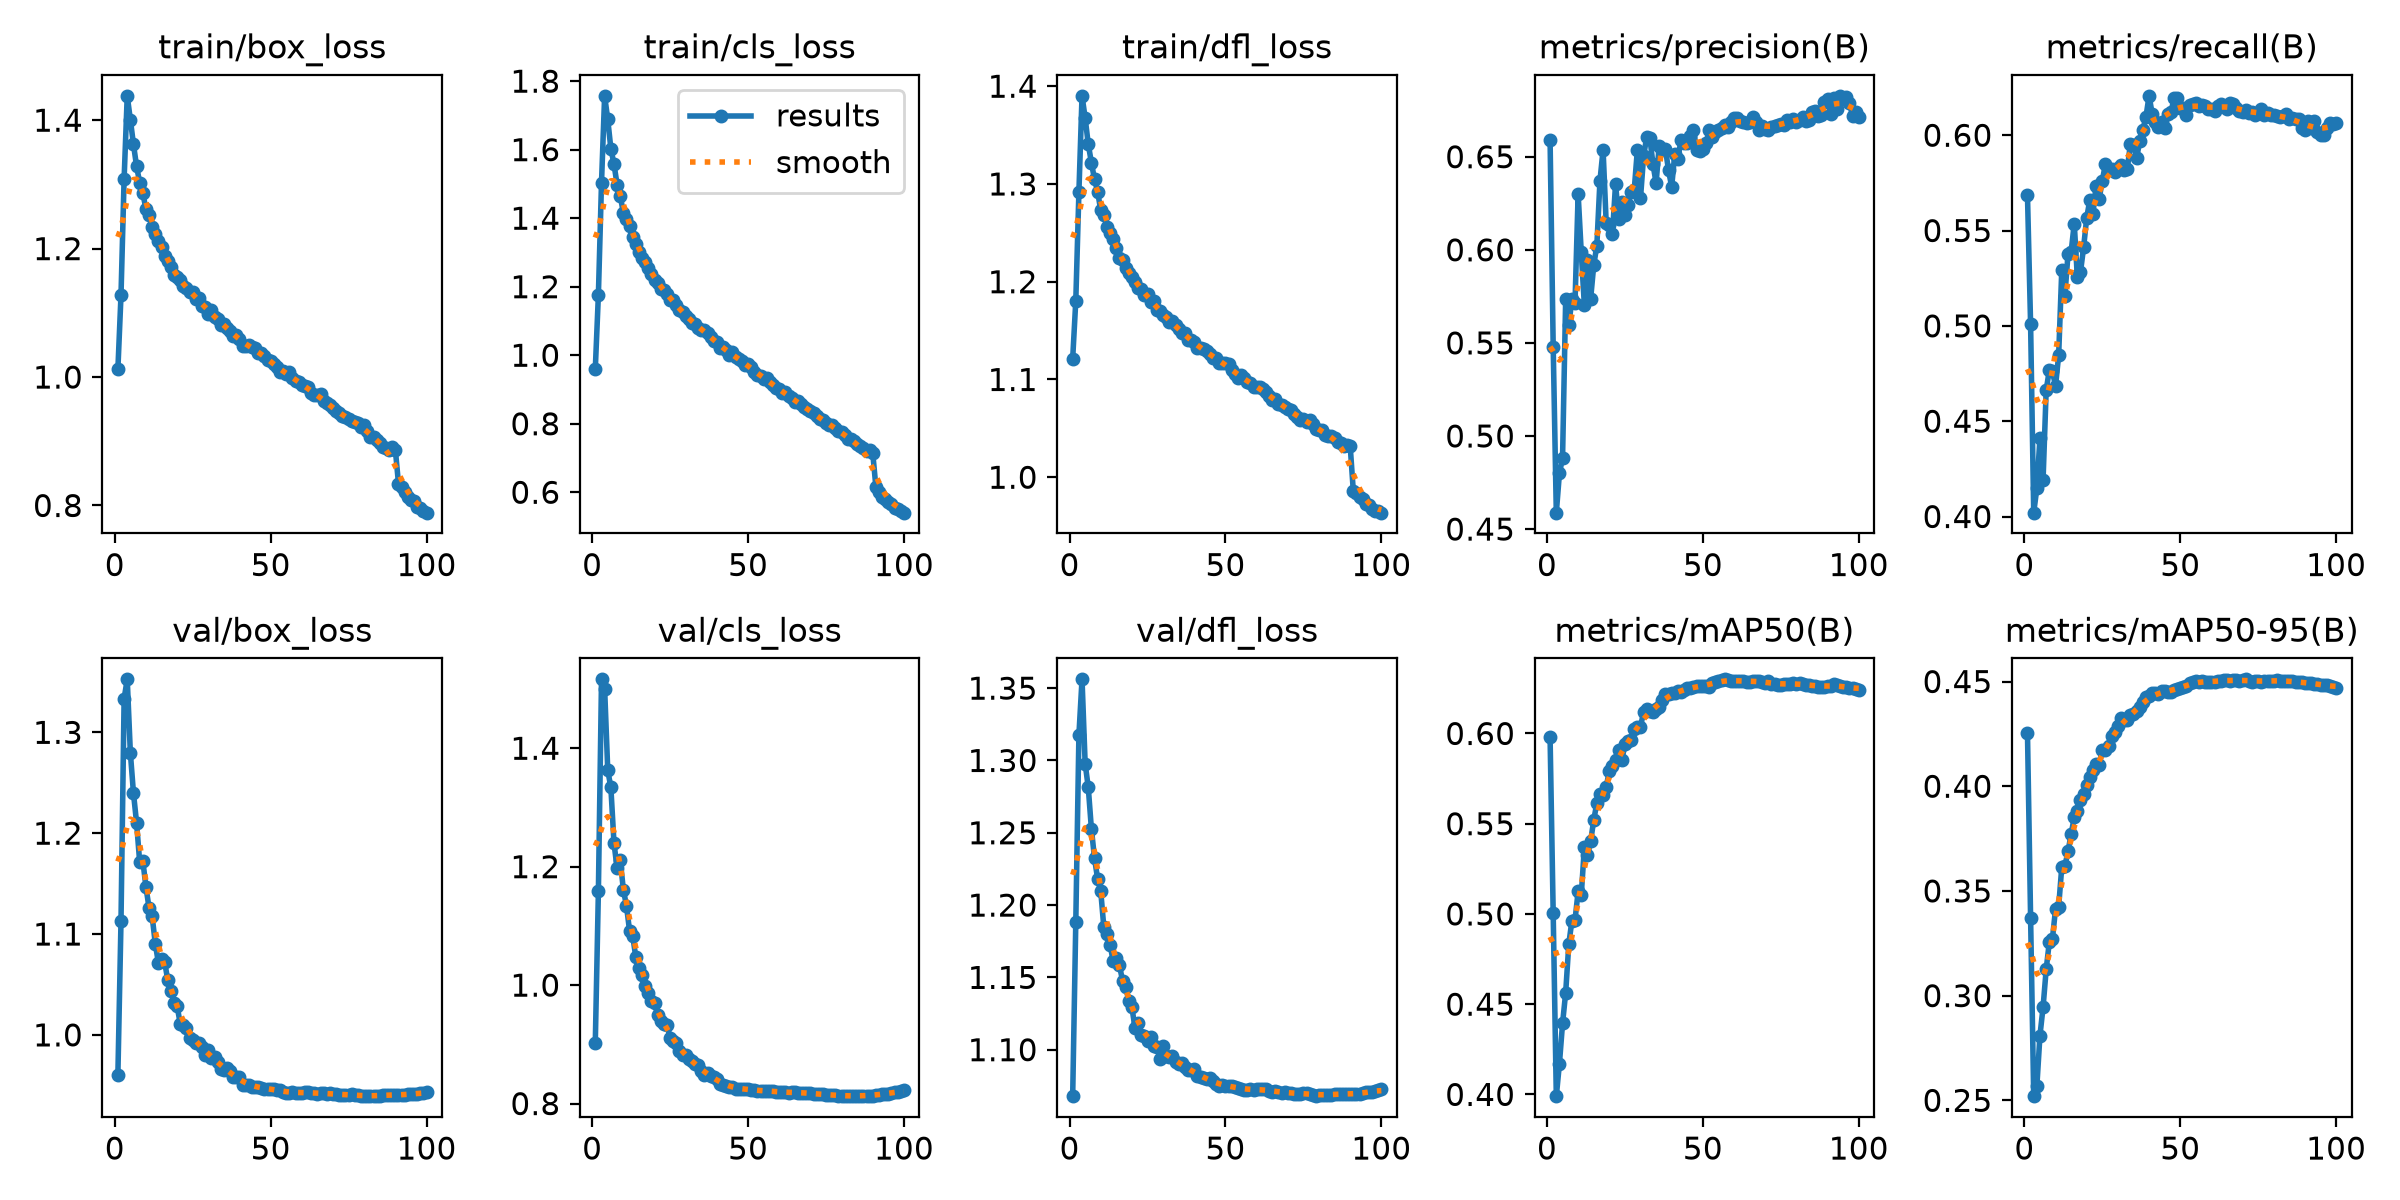

In [16]:
from IPython.display import Image, display

display(Image(filename=str(Path(results.save_dir) / "results.png")))

In [17]:
val_images_dir = Path(dataset_root) / "images" / "val"

preds = model.predict(
    source=str(val_images_dir),
    imgsz=640,
    conf=0.25,
    max_det=10,
    save=True,
)

print("Annotated predictions saved to:", model.predictor.save_dir)


WARNING 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

image 1/1357 C:\Users\shiif\Downloads\yoloduke\datasets\coco_instance_balanced5_undersampled\images\val\000000000724.jpg: 640x480 (no detections), 58.0ms
image 2/1357 C:\Users\shiif\Downloads\yoloduke\datasets\coco_instance_balanced5_undersampled\images\val\000000000785.jpg: 448x640 1 person, 137.1ms
image 3/1357 C:\Users\shiif\Downloads\yoloduke\datasets\coco_instance_balanced5_undersampled\images\val\000000000872.jpg: 640x640 2 persons, 59.7ms
image 4/1357